In [ ]:
import sys
sys.path.append(r'/Users/kostastsampourakis/Desktop/code/Python/projects/gaussfiltax')

import time

from jax import numpy as jnp
from jax import random as jr
from jax import lax, vmap, pmap, jacfwd, jacrev, debug, device_put, jit
from tensorflow_probability.substrates.jax.distributions import MultivariateNormalFullCovariance as MVN
# import tensorflow as tf
# tf.test.gpu_device_name()

import gaussfiltax.utils as utils
import gaussfiltax.inference as gf
from gaussfiltax.inference import ParamsUKF, _ukf_predict_nonadditive
from gaussfiltax.models import ParamsNLSSM, NonlinearSSM, ParamsBPF


import matplotlib.pyplot as plt
import matplotlib_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

ModuleNotFoundError: No module named 'gaussfiltax.utils'

## Models and simulations

In [ ]:
# Parameters
state_dim = 4
state_noise_dim = 2
emission_dim = 2
emission_noise_dim = 2
seq_length = 500
mu0 = 1.0 * jnp.array([-0.05, 0.001, 0.7, -0.05])
q0 = jnp.zeros(state_noise_dim)
r0 = jnp.zeros(emission_noise_dim)
Sigma0 = 1.0 * jnp.array([[0.1, 0.0, 0.0, 0.0],[0.0, 0.005, 0.0, 0.0],[0.0, 0.0, 0.1, 0.0],[0.0, 0.0, 0.0, 0.01]])
Q = 1e-6 * jnp.eye(state_noise_dim)
R = 25 * 1e-6  * jnp.eye(emission_noise_dim)

dt = 1.0
FCV = 1.0 * jnp.array([[1, dt, 0, 0],[0, 1, 0, 0],[0, 0, 1, dt],[0, 0, 0, 1]])
acc = 0.05
Omega = lambda x, acc: acc / jnp.sqrt(x[1]**2 + x[3]**2)
FCT =  lambda x, a: jnp.array([[1, jnp.sin(dt * Omega(x, a)) / Omega(x, a), 0, -(1-jnp.cos(dt * Omega(x, a))) / Omega(x, a)],
                            [0, jnp.cos(dt * Omega(x, a)), 0, -jnp.sin(dt * Omega(x, a))],
                            [0, (1-jnp.cos(dt * Omega(x, a))) / Omega(x, a), 1, jnp.sin(dt * Omega(x, a)) / Omega(x, a)],
                            [0, jnp.sin(dt * Omega(x, a)), 0, jnp.cos(dt * Omega(x, a))]])

G = jnp.array([[0.5, 0],[1, 0],[0, 0.5],[0, 1]])
fBOT = lambda x, q, u: FCV @ x + G @ q
fManBOT = lambda x, q, u: (0.5*(u-1)*(u-2) * FCV - u*(u-2) * FCT(x, acc) + 0.5*u*(u-1) * FCT(x, -acc)) @ x + G @ q
gBOT = lambda x, r, u: jnp.arctan2(x[2], x[0]) + r
gBOT2 = lambda x ,r, u: jnp.array([jnp.arctan2(x[2], x[0]), jnp.sqrt(x[0]**2 + x[2]**2)]) + r
gBOTlp = lambda x, y, u: MVN(loc = gBOT2(x, r0, u), covariance_matrix = R).log_prob(y)
# inputs = jnp.zeros((seq_length, 1))
# inputs = jnp.array([1]*int(2*seq_length/5) + [0]*int(seq_length/5) + [2]*int(2*seq_length/5)) # changepoint inputs
inputs = jr.choice(jr.PRNGKey(0), jnp.array([0, 1, 2]), shape = (seq_length, 1)) # random inputs
# inputs = vmap(lambda x: 2 * jnp.sin(0.1 * x)**2)(jnp.arange(seq_length)) # sine


In [ ]:
f = fManBOT
g = gBOT2
glp = gBOTlp

In [ ]:
# initialization
model = NonlinearSSM(state_dim, 
                     state_noise_dim, 
                     emission_dim, 
                     emission_noise_dim)

params = ParamsNLSSM(
    initial_mean=mu0,
    initial_covariance=Sigma0,
    dynamics_function=f,
    dynamics_noise_bias= q0,
    dynamics_noise_covariance=Q,
    emission_function=g,
    emission_noise_bias= r0,
    emission_noise_covariance=R,
)

params_bpf = ParamsBPF(
    initial_mean=mu0,
    initial_covariance=Sigma0,
    dynamics_function=f,
    dynamics_noise_bias=q0,
    dynamics_noise_covariance=Q,
    emission_function=g,
    emission_noise_bias=r0,
    emission_noise_covariance=R,
    emission_distribution_log_prob = glp
)

## Experiments

In [ ]:
verbose = False
Nsim = 100
gsf_mse = jnp.zeros(Nsim)
ugsf_mse = jnp.zeros(Nsim)
agsf_mse = jnp.zeros(Nsim)
uagsf_mse = jnp.zeros(Nsim)
bpf_mse = jnp.zeros(Nsim)
apf_mse = jnp.zeros(Nsim)
gspf_mse = jnp.zeros(Nsim)

gsf_norm = jnp.zeros((Nsim, seq_length))
ugsf_norm = jnp.zeros((Nsim, seq_length))
agsf_norm = jnp.zeros((Nsim, seq_length))
uagsf_norm = jnp.zeros((Nsim, seq_length))
bpf_norm = jnp.zeros((Nsim, seq_length))
apf_norm = jnp.zeros((Nsim, seq_length))
gspf_norm = jnp.zeros((Nsim, seq_length))

gsf_time = jnp.zeros(Nsim)
ugsf_time = jnp.zeros(Nsim)
agsf_time = jnp.zeros(Nsim)
uagsf_time = jnp.zeros(Nsim)
bpf_time = jnp.zeros(Nsim)
apf_time = jnp.zeros(Nsim)
gspf_time = jnp.zeros(Nsim)

next_key = jr.PRNGKey(0)
for i in range(Nsim):
    print('sim {}/{}'.format(i+1, Nsim))
    # Generate Data
    key0, key, next_key = jr.split(next_key, 3)
    print('key0: ', key0)
    print('key: ', key)
    states, emissions = model.sample(params, key0, seq_length, inputs = inputs)

    # GSF
    M = 100
    tin = time.time()
    posterior_filtered_gsf = gf.gaussian_sum_filter(params, emissions, M, 1, key, inputs)
    point_estimate_gsf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_filtered_gsf.means, posterior_filtered_gsf.weights), axis=0)
    tout = time.time()
    t_gsf= tout - tin
    print('       Time taken for GSF: ', tout - tin)

    # U-GSF
    tin = time.time()
    uparams = ParamsUKF(1,0,0)
    posterior_filtered_ugsf = gf.unscented_gaussian_sum_filter(params, uparams, emissions, M, 1, key, inputs)
    point_estimate_ugsf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_filtered_ugsf.means, posterior_filtered_ugsf.weights), axis=0)
    tout = time.time()
    t_ugsf= tout - tin
    print('       Time taken for UGSF: ', tout - tin)

    # AGSF
    opt_args = (0.85, 0.95)
    num_components = [100, 5, 5]
    tin = time.time()
    posterior_filtered_agsf, aux_outputs_agsf = gf.augmented_gaussian_sum_filter(params, emissions, num_components, rng_key = key, opt_args = opt_args, inputs=inputs)    
    point_estimate_agsf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_filtered_agsf.means, posterior_filtered_agsf.weights), axis=0)
    tout = time.time()
    t_agsf= tout - tin
    print('       Time taken for AGSF: ', tout - tin)

    # U-AGSF
    tin = time.time()
    # opt_args = (0.9, 0.95)
    # posterior_filtered_uagsf, aux_outputs = gf.unscented_agsf(params, uparams, emissions, num_components, rng_key = key, opt_args = opt_args, inputs=inputs)
    posterior_filtered_uagsf, aux_outputs_uagsf = gf.unscented_agsf(params, uparams, emissions, num_components, key, opt_args, inputs=inputs)
    point_estimate_uagsf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_filtered_uagsf.means, posterior_filtered_uagsf.weights), axis=0)
    tout = time.time()
    t_uagsf= tout - tin
    print('       Time taken for UAGSF: ', tout - tin)

    # BPF
    tin = time.time()
    num_particles = 100
    posterior_bpf = gf.bootstrap_particle_filter(params_bpf, emissions, num_particles, key, inputs)
    point_estimate_bpf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_bpf["particles"], posterior_bpf["weights"]), axis=0)
    tout = time.time()
    t_bpf = tout - tin
    print('       Time taken for BPF: ', tout - tin)

    # APF
    tin = time.time()
    posterior_apf = gf.auxiliary_particle_filter(params_bpf, emissions, num_particles, key, inputs)
    point_estimate_apf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_apf["particles"], posterior_apf["weights"]), axis=0)
    tout = time.time()
    t_apf = tout - tin
    print('       Time taken for APF: ', tout - tin)

    # # GS-PF
    # num_comp = 1
    # num_prt = 100
    # tin = time.time()
    # posterior_gspf = gf.gaussian_sum_particle_filter(params_bpf, emissions, num_comp, num_prt, key, inputs)
    # point_estimate_gspf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_gspf.means, posterior_gspf.weights), axis=0)
    # tout = time.time()
    # t_gspf = tout - tin
    # print('       Time taken for GSPF: ', tout - tin)


    # Computation of errors

    gsf_norm = gsf_norm.at[i].set(jnp.linalg.norm(point_estimate_gsf - states, axis = 1))
    ugsf_norm = ugsf_norm.at[i].set(jnp.linalg.norm(point_estimate_ugsf - states, axis = 1))
    agsf_norm = agsf_norm.at[i].set(jnp.linalg.norm(point_estimate_agsf - states, axis = 1))
    uagsf_norm = uagsf_norm.at[i].set(jnp.linalg.norm(point_estimate_uagsf - states, axis = 1))
    bpf_norm = bpf_norm.at[i].set(jnp.linalg.norm(point_estimate_bpf - states, axis = 1))
    apf_norm = apf_norm.at[i].set(jnp.linalg.norm(point_estimate_apf - states, axis = 1))
    # gspf_norm = gspf_norm.at[i].set(jnp.linalg.norm(point_estimate_gspf[:,(0,2)] - states[:,(0,2)], axis = 1))

    gsf_mse = gsf_mse.at[i].set(jnp.mean(gsf_norm[i]))
    ugsf_mse = ugsf_mse.at[i].set(jnp.mean(ugsf_norm[i]))
    agsf_mse = agsf_mse.at[i].set(jnp.mean(agsf_norm[i]))
    uagsf_mse = uagsf_mse.at[i].set(jnp.mean(uagsf_norm[i]))
    bpf_mse = bpf_mse.at[i].set(jnp.mean(bpf_norm[i]))
    apf_mse = apf_mse.at[i].set(jnp.mean(apf_norm[i]))
    gspf_mse = gspf_mse.at[i].set(jnp.mean(gspf_norm[i]))

    gsf_time = gsf_time.at[i].set(t_gsf)
    ugsf_time = ugsf_time.at[i].set(t_ugsf)
    agsf_time = agsf_time.at[i].set(t_agsf)
    uagsf_time = uagsf_time.at[i].set(t_uagsf)
    bpf_time = bpf_time.at[i].set(t_bpf)
    apf_time = apf_time.at[i].set(t_apf)
    # gspf_time = gspf_time.at[i].set(t_gspf)


sim 1/100
key0:  [2467461003  428148500]
key:  [3186719485 3840466878]
       Time taken for GSF:  1.153576135635376
       Time taken for UGSF:  1.456063985824585
       Time taken for AGSF:  3.1002628803253174
       Time taken for UAGSF:  4.4686195850372314
       Time taken for BPF:  0.8301408290863037
       Time taken for APF:  0.7517807483673096
sim 2/100
key0:  [4038682467 4049047219]
key:  [1123993949 1633776119]
       Time taken for GSF:  0.8287608623504639
       Time taken for UGSF:  1.3136608600616455
       Time taken for AGSF:  2.9721150398254395
       Time taken for UAGSF:  4.511696815490723
       Time taken for BPF:  0.5447349548339844
       Time taken for APF:  0.7918100357055664
sim 3/100
key0:  [3295730785 1907469606]
key:  [2175656443 3507338041]
       Time taken for GSF:  0.7966570854187012
       Time taken for UGSF:  1.4405481815338135
       Time taken for AGSF:  2.8930788040161133
       Time taken for UAGSF:  4.608582258224487
       Time taken for BPF: 

### PCRLB

In [ ]:
def pcrlb(key, model, params, seq_length, nsim, inputs):
    # initialize parameters
    f, h = params.dynamics_function, params.emission_function
    F_x, H_x = jacfwd(f, argnums=0), jacfwd(h, argnums=0)
    Qinv = G @ jnp.linalg.inv(params.dynamics_noise_covariance) @ G.T # DOn't forget to change this for additive model
    Rinv = jnp.linalg.inv(params.emission_noise_covariance)
    # sample nsim state trajectories
    keys = jr.split(key, nsim)
    states, _ = vmap(model.sample, in_axes=(None, 0, None, None))(params, keys, seq_length, inputs)
    # compute arrays of Jacobians
    f_jacobians = vmap(lambda x: vmap(F_x, in_axes=(0, None, 0))(x, params.dynamics_noise_bias, inputs))(states)
    h_jacobians = vmap(lambda x: vmap(H_x, in_axes=(0, None, 0))(x, params.emission_noise_bias, inputs))(states)

    # compute D arrays
    # TODO: remove the G @ Qinv @ G.T for additive model. Only use with additive model
    D11 = vmap(lambda F_array: jnp.sum(vmap(lambda F: F.T @ Qinv @ F)(F_array), axis=0)/nsim, in_axes=(1))(f_jacobians)
    D12 = - jnp.sum(f_jacobians, axis=0) / nsim @ Qinv
    D22 = vmap(lambda H_array: jnp.sum(vmap(lambda H: H.T @ Rinv @ H)(H_array), axis=0)/nsim + Qinv, in_axes=(1))(h_jacobians)

    def _step(carry, t):
        J_prev = carry
        D11_t, D12_t, D22_t = D11[t], D12[t], D22[t]
        J = D22_t - D12_t.T @ jnp.linalg.inv(J_prev + D11_t) @ D12_t
        carry = J
        stack = jnp.linalg.inv(J)
        return carry, stack
    
    J0 = 0 * jnp.eye(state_dim)
    J, CRLB_array = lax.scan(_step, J0, jnp.arange(seq_length))
    return CRLB_array

key, subkey = jr.split(jr.PRNGKey(0))
CRLB = pcrlb(subkey, model, params, seq_length, 10000, inputs)

### OUTPUT

In [ ]:
import pandas as pd

idx = jnp.array([0,2])
arr = CRLB[:, idx[:, None], idx]
crlb_val = jnp.mean(jnp.trace(arr, axis1=1, axis2=2))

# Remove NaNs and compute success percentage
ind_gsf = jnp.unique(jnp.argwhere(jnp.isnan(gsf_mse)))
gsf_mse = jnp.delete(gsf_mse, ind_gsf, axis = 0)
gsf_success_pct = int(100 - 100*len(ind_gsf) / Nsim)

ind_ugsf = jnp.unique(jnp.argwhere(jnp.isnan(ugsf_mse)))
ugsf_mse = jnp.delete(ugsf_mse, ind_ugsf, axis = 0)
ugsf_success_pct = int(100 - 100* len(ind_ugsf) / Nsim)

ind_agsf = jnp.unique(jnp.argwhere(jnp.isnan(agsf_mse)))
agsf_mse = jnp.delete(agsf_mse, ind_agsf, axis = 0)
agsf_success_pct = int(100 - 100*len(ind_agsf) / Nsim)

ind_uagsf = jnp.unique(jnp.argwhere(jnp.isnan(uagsf_mse)))
uagsf_mse = jnp.delete(uagsf_mse, ind_uagsf, axis = 0)
uagsf_success_pct = int(100 - 100*len(ind_uagsf) / Nsim)

ind_bpf = jnp.unique(jnp.argwhere(jnp.isnan(bpf_mse)))
bpf_mse = jnp.delete(bpf_mse, ind_bpf, axis = 0)
bpf_success_pct = int(100 - 100*len(ind_bpf) / Nsim)

ind_apf = jnp.unique(jnp.argwhere(jnp.isnan(apf_mse)))
apf_mse = jnp.delete(apf_mse, ind_apf, axis = 0)
apf_success_pct = int(100 - 100*len(ind_apf) / Nsim)

ind_gspf = jnp.unique(jnp.argwhere(jnp.isnan(gspf_mse)))
gspf_mse = jnp.delete(gspf_mse, ind_gspf, axis = 0)
gspf_success_pct = int(100 - 100*len(ind_gspf) / Nsim)


keys = jr.split(jr.PRNGKey(0), 7)
B = 100
gsf_boot = utils.bootstrap(keys[0], gsf_mse, B)
ugsf_boot = utils.bootstrap(keys[1], ugsf_mse, B)
agsf_boot = utils.bootstrap(keys[2], agsf_mse, B)
uagsf_boot = utils.bootstrap(keys[3], uagsf_mse, B)
bpf_boot = utils.bootstrap(keys[4], bpf_mse, B)
apf_boot = utils.bootstrap(keys[5], apf_mse, B)
gspf_boot = utils.bootstrap(keys[6], gspf_mse, B)

gsf_amse = jnp.mean(gsf_boot)
ugsf_amse = jnp.mean(ugsf_boot)
agsf_amse = jnp.mean(agsf_boot)
uagsf_amse = jnp.mean(uagsf_boot)
bpf_amse = jnp.mean(bpf_boot)
apf_amse = jnp.mean(apf_boot)
gspf_amse = jnp.mean(gspf_boot)

gsf_atime = jnp.mean(gsf_time)
ugsf_atime = jnp.mean(ugsf_time)
agsf_atime = jnp.mean(agsf_time)
uagsf_atime = jnp.mean(uagsf_time)
bpf_atime = jnp.mean(bpf_time)
apf_atime = jnp.mean(apf_time)
gspf_atime = jnp.mean(gspf_time)

gsf_tab_out = '${:2.3f}\pm{:2.3f}({}\%)$'.format(gsf_amse, jnp.std(gsf_boot), gsf_success_pct)
ugsf_tab_out = '${:2.3f}\pm{:2.3f}({}\%)$'.format(ugsf_amse, jnp.std(ugsf_boot), ugsf_success_pct)
agsf_tab_out = '${:2.3f}\pm{:2.3f}({}\%)$'.format(agsf_amse, jnp.std(agsf_boot), agsf_success_pct)
uagsf_tab_out = '${:2.3f}\pm{:2.3f}({}\%)$'.format(uagsf_amse, jnp.std(uagsf_boot), uagsf_success_pct)
bpf_tab_out = '${:2.3f}\pm{:2.3f}({}\%)$'.format(bpf_amse, jnp.std(bpf_boot), bpf_success_pct)
apf_tab_out = '${:2.3f}\pm{:2.3f}({}\%)$'.format(apf_amse, jnp.std(apf_boot), apf_success_pct)
gspf_tab_out = '${:2.3f}\pm{:2.3f}({}\%)$'.format(gspf_amse, jnp.std(gspf_boot), gspf_success_pct)
crlb_tab_out = '${:2.5f}$'.format(crlb_val)

gsf_tab_out1 = '${:2.2f}\pm{:2.2f}$'.format(gsf_atime, jnp.std(gsf_time))
ugsf_tab_out1 = '${:2.2f}\pm{:2.2f}$'.format(ugsf_atime, jnp.std(ugsf_time))
agsf_tab_out1 = '${:2.2f}\pm{:2.2f}$'.format(agsf_atime, jnp.std(agsf_time))
uagsf_tab_out1 = '${:2.2f}\pm{:2.2f}$'.format(uagsf_atime, jnp.std(uagsf_time))
bpf_tab_out1 = '${:2.2f}\pm{:2.2f}$'.format(bpf_atime, jnp.std(bpf_time))
apf_tab_out1 = '${:2.2f}\pm{:2.2f}$'.format(apf_atime, jnp.std(apf_time))
gspf_tab_out1 = '${:2.2f}\pm{:2.2f}$'.format(gspf_atime, jnp.std(gspf_time))
crb_tab_out1 = ' '

df = pd.DataFrame(columns = [' ','RMSE','time(s)'])
# df[' '] = ['GSF', 'AGSF', 'AGSF Optimal', 'BPF']
# df['RMSE'] = [gsf_tab_out, agsf_tab_out, agsf_opt_tab_out, bpf_tab_out]
# df['time(s)'] = [gsf_tab_out1, agsf_tab_out1, agsf_opt_tab_out1, bpf_tab_out1]
df[' '] = ['GSF','UGSF', 'AGSF', 'UAGSF', 'BPF', 'APF', 'GSPF', 'CRLB']
df['RMSE'] = [gsf_tab_out, ugsf_tab_out, agsf_tab_out, uagsf_tab_out, bpf_tab_out, apf_tab_out, gspf_tab_out, crlb_tab_out]
df['time(s)'] = [gsf_tab_out1, ugsf_tab_out1, agsf_tab_out1, uagsf_tab_out1, bpf_tab_out1, apf_tab_out1, gspf_tab_out1, crb_tab_out1]
print(df.to_latex(index=False))
df

\begin{tabular}{lll}
\toprule
  & RMSE & time(s) \\
\midrule
GSF & $0.119\pm0.003(8\%)$ & $0.91\pm0.37$ \\
UGSF & $0.686\pm0.497(94\%)$ & $1.40\pm0.26$ \\
AGSF & $0.031\pm0.003(100\%)$ & $3.18\pm0.77$ \\
UAGSF & $0.027\pm0.002(100\%)$ & $4.57\pm0.47$ \\
BPF & $19.996\pm2.392(100\%)$ & $0.60\pm0.29$ \\
APF & $19.078\pm2.251(100\%)$ & $0.82\pm0.07$ \\
GSPF & $0.000\pm0.000(100\%)$ & $0.00\pm0.00$ \\
CRLB & $0.00006$ &   \\
\bottomrule
\end{tabular}



,,RMSE,time(s)
0,GSF,$0.119\pm0.003(8\%)$,$0.91\pm0.37$
1,UGSF,$0.686\pm0.497(94\%)$,$1.40\pm0.26$
2,AGSF,$0.031\pm0.003(100\%)$,$3.18\pm0.77$
3,UAGSF,$0.027\pm0.002(100\%)$,$4.57\pm0.47$
4,BPF,$19.996\pm2.392(100\%)$,$0.60\pm0.29$
5,APF,$19.078\pm2.251(100\%)$,$0.82\pm0.07$
6,GSPF,$0.000\pm0.000(100\%)$,$0.00\pm0.00$
7,CRLB,$0.00006$,


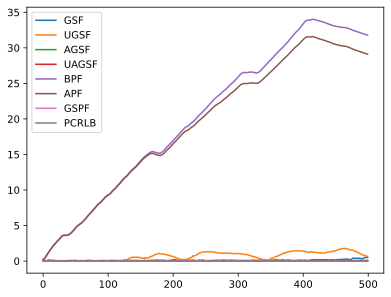

In [ ]:
idx = jnp.arange(Nsim)
plt.plot(jnp.mean(gsf_norm[jnp.setdiff1d(idx,ind_gsf)], axis=0), label='GSF')
plt.plot(jnp.mean(ugsf_norm[jnp.setdiff1d(idx,ind_ugsf)], axis=0), label='UGSF')
plt.plot(jnp.mean(agsf_norm[jnp.setdiff1d(idx,ind_agsf)], axis=0), label='AGSF')
plt.plot(jnp.mean(uagsf_norm[jnp.setdiff1d(idx,ind_uagsf)], axis=0), label='UAGSF')
plt.plot(jnp.mean(bpf_norm[jnp.setdiff1d(idx,ind_bpf)], axis=0), label='BPF')
plt.plot(jnp.mean(apf_norm[jnp.setdiff1d(idx,ind_apf)], axis=0), label='APF')
plt.plot(jnp.mean(gspf_norm[jnp.setdiff1d(idx,ind_gspf)], axis=0), label='GSPF')
plt.plot(jnp.trace(arr, axis1=1, axis2=2), label='PCRLB')
plt.legend()
plt.show()

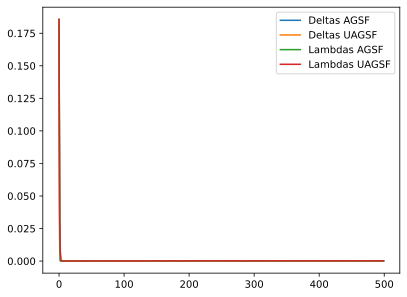

In [ ]:
plt.plot(jnp.trace(aux_outputs_agsf['Deltas'], axis1=2, axis2=3)[:,0], label = 'Deltas AGSF')
plt.plot(jnp.trace(aux_outputs_uagsf['Deltas'], axis1=2, axis2=3)[:,0], label = 'Deltas UAGSF')
plt.plot(jnp.trace(aux_outputs_agsf['Lambdas'], axis1=2, axis2=3)[:,0], label = 'Lambdas AGSF')
plt.plot(jnp.trace(aux_outputs_uagsf['Lambdas'], axis1=2, axis2=3)[:,0], label = 'Lambdas UAGSF')
plt.legend()
plt.show()

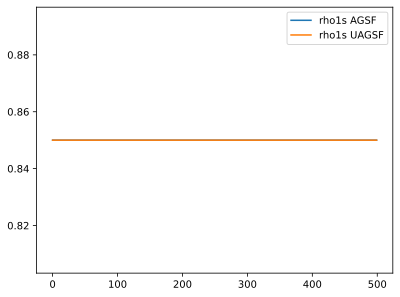

In [ ]:
plt.plot(aux_outputs_agsf['rho1s'][:,0], label = 'rho1s AGSF')
plt.plot(aux_outputs_uagsf['rho1s'][:,0], label = 'rho1s UAGSF')
plt.legend()
plt.show()

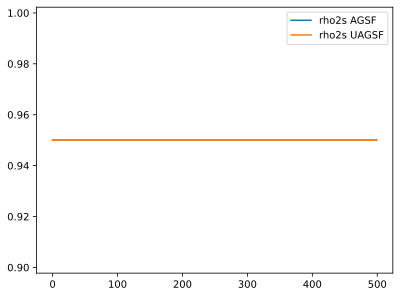

In [ ]:
plt.plot(aux_outputs_agsf['rho2s'][:,0], label = 'rho2s AGSF')
plt.plot(aux_outputs_uagsf['rho2s'][:,0], label = 'rho2s UAGSF')
plt.legend()
plt.show()

In [ ]:
agsf_mse

Array([0.02408698, 0.01779666, 0.02099403, 0.11393713, 0.0787267 ,
       0.00474178, 0.00647023, 0.06281795, 0.02836484, 0.02078545,
       0.01550352, 0.01670446, 0.03440601, 0.03735044, 0.01924038,
       0.02517375, 0.00679844, 0.01840548, 0.02534593, 0.06140218,
       0.05980773, 0.03776288, 0.02219686, 0.04539363, 0.1259396 ,
       0.0212525 , 0.0063236 , 0.01578798, 0.05659037, 0.00889142,
       0.00686019, 0.03228349, 0.05268176, 0.02829122, 0.02674806,
       0.04389146, 0.03869943, 0.01446911, 0.00869157, 0.0277089 ,
       0.06181259, 0.02644528, 0.04195817, 0.03345992, 0.00652261,
       0.04586016, 0.01632519, 0.00676747, 0.01119967, 0.03634537,
       0.00865375, 0.02103964, 0.00643202, 0.01721013, 0.03046789,
       0.02472542, 0.04260318, 0.03932809, 0.06817241, 0.01395018,
       0.0131012 , 0.01267925, 0.01005196, 0.03164549, 0.00588388,
       0.01504504, 0.30516097, 0.02048212, 0.02920193, 0.06876546,
       0.00976781, 0.01387784, 0.06665135, 0.02360462, 0.01081